# SI-REKTA: Sistem Informasi Rekomendasi Dosen Pembimbing Tugas Akhir
## Pendekatan Direct Dual-Source Late-Fusion TF-IDF dan Explainable AI (XAI) untuk Rekomendasi Calon Pembimbing 1 Tugas Akhir

The project consists of the following stages:
• Problem Identification
• System Requirements Analysis
• Data Analysis
• Data Preprocessing
• Data Processing Procedures
• Machine Learning Algorithm Selection
• Model Development
• Model Evaluation
• Model Storage
• Information System Design
• Model Integration into the System
• User Interface Implementation

---

### Metadata Akademik
- **Mata Kuliah:** Machine Learning (DSI61133) — Semester 5 (Tahun Akademik 2025/2026)
- **Program Studi / Departemen:** Departemen Sistem Informasi
- **Fakultas / Institusi:** Fakultas Teknologi Informasi, Universitas Andalas
- **Dosen Pengampu:** Febby Apri Wenando, M.Eng., Ph.D. & Aina Hubby Aziira, M.Eng.
- **Standar Metodologi:** CRISP-ML(Q) (*Cross-Industry Standard Process for the Development of Machine Learning Applications with Quality Assurance*)

---

### 1. Latar Belakang Masalah
Pemilihan Dosen Pembimbing Tugas Akhir (TA-01/TA-02) di Departemen Sistem Informasi FTI Universitas Andalas sering kali menghadapi kendala subjektivitas, asimetri informasi kompetensi riset dosen, serta beban bimbingan yang terkonsentrasi secara timpang pada dosen-dosen senior.

Secara teknis data mining, audit korpus data riwayat bimbingan historis 2017–2024 (`Judul_TA.csv` sebanyak 625 rekaman) memperlihatkan kendala kritis berupa **Cold-Start Problem**: dari 17 Dosen Tetap Aktif DSI Unand, terdapat 5 dosen yang memiliki **0 riwayat bimbingan sebagai Pembimbing 1 (P1)**. Jika sistem rekomendasi hanya mengandalkan riwayat bimbingan skripsi masa lalu, kelima dosen tersebut tidak akan pernah terprediksi atau direkomendasikan, sehingga menciptakan *bias* representasi yang merugikan baik bagi dosen maupun mahasiswa.

### 2. Konsep Solusi Teknis: Direct Recommendation via Dual-Source Late-Fusion & XAI
Untuk mengatasi permasalahan *cold-start* secara saintifik dan adil, SI-REKTA mengintegrasikan **Dual-Source Dataset** yang memadukan riwayat bimbingan skripsi (`Judul_TA.csv`) dan publikasi ilmiah resmi dosen (`Publikasi_Dosen.csv` sebanyak 643 artikel):
1. **Direct Recommendation (Non-KK Intermediate):** Pencocokan semantik dilakukan secara langsung (*direct matching*) antara usulan judul/ide skripsi mahasiswa dengan profil representasi 17 Dosen Tetap Aktif tanpa menggunakan klasifikasi antara Kelompok Keahlian (KK), meminimalkan risiko *cascading error* klasifikasi tingkat pertama.
2. **Dynamic Late-Fusion Scoring:** Mengombinasikan kemiripan kosinus usulan mahasiswa terhadap korpus riwayat bimbingan ($S_{TA}$) dan korpus publikasi riset dosen ($S_{Pub}$) dengan mekanisme pembobotan adaptif:
   $$\text{Final Score}(d) = \alpha \cdot S_{TA}(d) + (1 - \alpha) \cdot S_{Pub}(d)$$
   Bagi 5 dosen berkategori *cold-start* (riwayat P1 = 0), bobot otomatis dialihkan penuh ($\alpha = 0$, $1 - \alpha = 1.0$) ke profil publikasi riset dosen, menjamin keterpilihan yang objektif berbasis kepakaran ilmiah mutakhir.
3. **Explainable AI (XAI):** Setiap rekomendasi Top-3 dilengkapi persentase skor kecocokan, ekstraksi kata kunci representatif (*salient terms/N-grams*), serta sitasi judul karya ilmiah dosen pendukung agar mahasiswa dan departemen memperoleh transparansi penuh (*white-box justification*).

---

### 3. Penyelarasan 12 Tahapan Proyek ML 2026 dengan Standar CRISP-ML(Q)

| No | 12 Tahapan Resmi Proyek ML 2026 | Fase CRISP-ML(Q) Terkait | Fokus Implementasi pada SI-REKTA | Lingkup Lingkungan Implementasi |
| :---: | :--- | :--- | :--- | :--- |
| 1 | **Problem Identification** | Fase 1: Business and Data Understanding | Identifikasi kendala TA-01/TA-02, ketimpangan bimbingan, dan fenomena *cold-start* 5 dosen. | Notebook (`si_rekta_model_development.ipynb`) |
| 2 | **System Requirements Analysis** | Fase 1: Business and Data Understanding | Spesifikasi batasan 17 Dosen Tetap Aktif, metrik Top-3, latensi inferensi, dan fungsionalitas XAI. | Notebook (`si_rekta_model_development.ipynb`) |
| 3 | **Data Analysis** | Fase 1: Business and Data Understanding | Audit kualitas dataset dwisumber (`Judul_TA.csv` & `Publikasi_Dosen.csv`) via statistik deskriptif dan EDA. | Notebook (`si_rekta_model_development.ipynb`) |
| 4 | **Data Preprocessing** | Fase 2: Data Preparation | Normalisasi teks teknis domain IT, *case folding*, pembersihan simbol/angka, dan penyaringan stopword akademik khusus. | Notebook (`si_rekta_model_development.ipynb`) |
| 5 | **Data Processing Procedures** | Fase 2: Data Preparation | Kanonikalisasi nama 17 entitas dosen, agregasi korpus per dosen, serta ekstraksi fitur TF-IDF (Unigram & Bigram). | Notebook (`si_rekta_model_development.ipynb`) |
| 6 | **Machine Learning Algorithm Selection** | Fase 3: Modeling | Evaluasi representasi berbasis Information Retrieval & Cosine Similarity versus algoritma parametrik/probabilistik. | Notebook (`si_rekta_model_development.ipynb`) |
| 7 | **Model Development** | Fase 3: Modeling | Pembangunan mesin inferensi Direct Dual-Source Late-Fusion berbobot adaptif dan modul Explainability (XAI). | Notebook (`si_rekta_model_development.ipynb`) |
| 8 | **Model Evaluation** | Fase 4: Evaluation | Pengujian performa sistem menggunakan metrik Top-1 Accuracy, Top-3 Recall/Accuracy, MRR@3, dan pengujian skenario *cold-start*. | Notebook (`si_rekta_model_development.ipynb`) |
| 9 | **Model Storage** | Fase 5: Deployment Preparation | Serialisasi artefak matriks TF-IDF, vectorizer, lookup dictionary, dan metadata profil 17 dosen ke `si_rekta_pipeline.joblib`. | Notebook (`si_rekta_model_development.ipynb`) |
| 10 | **Information System Design** | Fase 5: System Deployment | Perancangan arsitektur modular tiga lapis (*Three-Tier Architecture*): Client UI, RESTful API Engine, dan Storage Layer. | Aplikasi Web & Production Deployment |
| 11 | **Model Integration into the System** | Fase 5: System Deployment | Integrasi biner model `joblib` ke dalam web service backend berbasis Python (FastAPI/Flask) dengan endpoint inferensi real-time. | Aplikasi Web & Production Deployment |
| 12 | **User Interface Implementation** | Fase 5: System Deployment | Pengembangan antarmuka interaktif responsif bagi mahasiswa untuk input draf judul TA dan visualisasi kartu Top-3 rekomendasi + XAI. | Aplikasi Web & Production Deployment |

---

### 4. Daftar Resmi 17 Dosen Tetap Aktif DSI Unand

Ruang lingkup rekomendasi SI-REKTA dikunci secara ketat hanya pada **17 Dosen Tetap Aktif Departemen Sistem Informasi Universitas Andalas**, yang dikelompokkan ke dalam dua klaster status bimbingan historis P1:

| No | Nama Dosen Beserta Gelar Akademik | Status Riwayat P1 (Dataset 1) | Keterangan Status Bimbingan |
| :---: | :--- | :---: | :--- |
| 1 | **Ricky Akbar, M.Kom.** | $\ge 1$ Riwayat (149 Skripsi) | Dosen Bimbingan Aktif (Aktif Membimbing P1) |
| 2 | **Husnil Kamil, M.T.** | $\ge 1$ Riwayat (93 Skripsi) | Dosen Bimbingan Aktif (Aktif Membimbing P1) |
| 3 | **Prof. Surya Afnarius, Ph.D.** | $\ge 1$ Riwayat (87 Skripsi) | Dosen Bimbingan Aktif (Aktif Membimbing P1) |
| 4 | **Haris Suryamen, M.Sc.** | $\ge 1$ Riwayat (67 Skripsi) | Dosen Bimbingan Aktif (Aktif Membimbing P1) |
| 5 | **Hasdi Putra, M.T.** | $\ge 1$ Riwayat (49 Skripsi) | Dosen Bimbingan Aktif (Aktif Membimbing P1) |
| 6 | **Fajril Akbar, M.Sc.** | $\ge 1$ Riwayat (38 Skripsi) | Dosen Bimbingan Aktif (Aktif Membimbing P1) |
| 7 | **Rahmatika Pratama Santi, M.T.** | $\ge 1$ Riwayat (30 Skripsi) | Dosen Bimbingan Aktif (Aktif Membimbing P1) |
| 8 | **Dwi Welly Sukma Nirad, M.T.** | $\ge 1$ Riwayat (18 Skripsi) | Dosen Bimbingan Aktif (Aktif Membimbing P1) |
| 9 | **Afriyanti Dwi Kartika, S.Pd., M.T.** | $\ge 1$ Riwayat (13 Skripsi) | Dosen Bimbingan Aktif (Aktif Membimbing P1) |
| 10 | **Ullya Mega Wahyuni, M.Kom.** | $\ge 1$ Riwayat (13 Skripsi) | Dosen Bimbingan Aktif (Aktif Membimbing P1) |
| 11 | **Jefril Rahmadoni, M.Kom.** | $\ge 1$ Riwayat (10 Skripsi) | Dosen Bimbingan Aktif (Aktif Membimbing P1) |
| 12 | **Hafizah Hanim, M.Kom.** | $\ge 1$ Riwayat (1 Skripsi) | Dosen Bimbingan Aktif (Aktif Membimbing P1) |
| 13 | **Febby Apri Wenando, M.Eng., Ph.D.** | **0 Riwayat** | **Cold-Start Dosen** (Profil bersumber 100% dari publikasi riset) |
| 14 | **Adi Arga Arifnur, M.Kom.** | **0 Riwayat** | **Cold-Start Dosen** (Profil bersumber 100% dari publikasi riset) |
| 15 | **Nisa Dwi Angresti, M.Kom.** | **0 Riwayat** | **Cold-Start Dosen** (Profil bersumber 100% dari publikasi riset) |
| 16 | **Hafzatin Nurlatifa, M.Eng.** | **0 Riwayat** | **Cold-Start Dosen** (Profil bersumber 100% dari publikasi riset) |
| 17 | **Aina Hubby Aziira, M.Eng.** | **0 Riwayat** | **Cold-Start Dosen** (Profil bersumber 100% dari publikasi riset) |

### 🛠️ Pemuatan Pustaka (Library Importation) & Konfigurasi Lingkungan Kerja

Ekosistem pengembangan model **SI-REKTA** dibangun menggunakan tumpukan pustaka (*library stack*) standar industri Python untuk kebutuhan manipulasi data numerik dan tabel (`pandas`, `numpy`), pembersihan teks teknis (`re`, `string`), pemodelan *Information Retrieval* dan *Machine Learning* berbasis `scikit-learn` (`TfidfVectorizer`, `cosine_similarity`, `train_test_split`, `KFold`, `StratifiedKFold`), serta serialisasi artefak model pipeline mandiri (`joblib`). Seluruh dependensi ini dikonfigurasi bersama pustaka visualisasi (`matplotlib` dan `seaborn`) dengan pengaturan tema grafis minimalis dan penekanan pesan peringatan (*warning suppression*) guna menjamin eksekusi notebook yang bersih, modular, dan terstandardisasi mengacu pada metodologi CRISP-ML(Q).

---

#### 💡 Ringkasan Modul & Pustaka Utama

| Kategori Modul | Pustaka / Fungsi Utama | Peran Komputasi dalam Proyek |
| :--- | :--- | :--- |
| **Data Manipulation** | `pandas`, `numpy` | Penanganan struktur DataFrame korpus skripsi & publikasi, agregasi matriks, dan kalkulasi array numerik. |
| **Text Processing** | `re`, `string` | Normalisasi ekspresi reguler, pembersihan karakter non-alfabetis, dan sanitasi tanda baca. |
| **Feature & Similarity** | `TfidfVectorizer`, `cosine_similarity` | Ekstraksi fitur leksikal n-gram dokumen dan komputasi kedekatan sudut semantik usulan judul mahasiswa. |
| **Validation Strategy** | `train_test_split`, `KFold`, `StratifiedKFold` | Skema partisi data berstrata guna menjamin keadilan evaluasi (*fairness evaluation*) di tengah ketimpangan data. |
| **Serialization & Utility**| `joblib`, `os`, `time`, `warnings` | Ekspor artefak biner pipeline mandiri (`.joblib`), pencatatan latensi inferensi, dan supresi log sistem. |
| **Visualization** | `matplotlib.pyplot`, `seaborn` | Visualisasi grafik sebaran data, distribusi frekuensi bimbingan dosen, dan matriks evaluasi model. |

In [ ]:
# ==============================================================================
# TAHAP PENYIAPAN LINGKUNGAN KERJA & PEMUATAN DEPENDENSI UTAMA (SI-REKTA)
# ==============================================================================

# Pustaka Utilitas Sistem & Serialisasi
import os
import time
import warnings
import joblib

# Pustaka Manipulasi & Komputasi Numerik
import numpy as np
import pandas as pd

# Pustaka Pemrosesan Teks & Ekspresi Reguler
import re
import string

# Pustaka Machine Learning, Ekstraksi Fitur & Evaluasi (Scikit-Learn)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold

# Pustaka Visualisasi Data
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------------------------
# Konfigurasi Lingkungan Visualisasi & Penekanan Peringatan
# ------------------------------------------------------------------------------
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['axes.unicode_minus'] = False

> **🔍 Status Lingkungan Eksekusi:** Seluruh pustaka pendukung analisis data, NLP, pemodelan Machine Learning, dan visualisasi telah berhasil diimpor ke dalam memori lingkungan kerja tanpa menghasilkan galat (*zero error*) maupun pesan peringatan.

### 📂 Tahap 3: Data Analysis — Pemuatan & Audit Struktur Awal Dataset 1 (Skripsi)

Audit struktur dataset historis tugas akhir (`Judul_TA.csv`) dilakukan untuk mengonfirmasi kelengkapan rekaman dan integritas fitur teks sebelum memasuki tahap rekayasa data (*data engineering*). Berkas ini merekam 625 riwayat skripsi alumni DSI Unand (2017–2024) dengan delimiter titik koma (`;`).

Pemeriksaan awal difokuskan pada:
- Pembersihan spasi penamaan kolom (*whitespace stripping*).
- Identifikasi dimensi matriks tabular.
- Pengecekan nilai kosong (*missing values*) pada atribut krusial usulan judul (`judul_ta`) serta label pembimbing utama (`pembimbing_1`).

Langkah ini bertujuan untuk memastikan tidak ada galat struktural yang menghambat pembentukan korpus bimbingan historis.

In [ ]:
# ==============================================================================
# TAHAP 3: DATA ANALYSIS - PEMUATAN & AUDIT STRUKTUR AWAL DATASET 1 (SKRIPSI)
# ==============================================================================

file_path_ta = "Judul_TA.csv"

# 1. Pemuatan berkas CSV dengan delimiter titik koma dan fallback encoding
try:
  df_skripsi = pd.read_csv(file_path_ta, sep=";", encoding="utf-8")
except UnicodeDecodeError:
  df_skripsi = pd.read_csv(file_path_ta, sep=";", encoding="latin1")

# 2. Sanitasi penamaan kolom dari spasi berlebih
df_skripsi.columns = df_skripsi.columns.str.strip()

# 3. Analisis dimensi dan audit missing values pada kolom esensial
total_baris, total_kolom = df_skripsi.shape
missing_judul = df_skripsi["judul_ta"].isna().sum()
missing_p1 = df_skripsi["pembimbing_1"].isna().sum()

print("=" * 70)
print("RINGKASAN AUDIT DATASET 1 (Judul_TA.csv)")
print("=" * 70)
print(f"Dimensi Dataframe           : {total_baris} baris x {total_kolom} kolom")
print(f"Missing Value 'judul_ta'    : {missing_judul} rekaman")
print(f"Missing Value 'pembimbing_1': {missing_p1} rekaman")
print("=" * 70)
print("Pratinjau 5 Baris Pertama:")

# Menampilkan 5 baris pertama data tabular
df_skripsi.head()

RINGKASAN AUDIT DATASET 1 (Judul_TA.csv)
Dimensi Dataframe           : 625 baris x 8 kolom
Missing Value 'judul_ta'    : 0 rekaman
Missing Value 'pembimbing_1': 1 rekaman
Pratinjau 5 Baris Pertama:


,no,judul_ta,nama_mahasiswa,nim,tahun,pembimbing_1,pembimbing_2,poster
0,1,Pembangunan Aplikasi Mobile GIS Wisata Sejarah...,Istigfar Rahman,1.010962e+09,2014,"Prof. Surya Afnarius, Ph.D",-,-
1,2,Pembangunan Aplikasi Mobile Geographic Informa...,Faisal Khalid,1.010961e+09,2014,"Prof.Surya Afnarius,Ph.D",-,-
2,3,Pembangunan Aplikasi Mobile Gis Pariwisata : E...,Devo Frihandana,1.010962e+09,2014,"Prof.Surya Afnarius,Ph.D",-,-
3,4,Pembangunan Aplikasi Mobile GIS Wisata Alam Pr...,Febrinanda Endriz Pratama,1.010962e+09,2014,"Prof.Surya Afnarius,Ph.D",-,-
4,5,Pembangunan Aplikasi Mobile Geographic Informa...,Vivi Mulya Ningsih,1.010962e+09,2014,"Prof.Surya Afnarius,Ph.D",-,-


> ### 🔍 Interpretasi Hasil Pemuatan Data
>
> Eksekusi audit berhasil memuat DataFrame `df_skripsi` dengan dimensi tepat **625 baris dan 8 kolom** (`no`, `judul_ta`, `nama_mahasiswa`, `nim`, `tahun`, `pembimbing_1`, `pembimbing_2`, `poster`).
>
> **Temuan Kunci:**
> - **Integritas Atribut Utama:** Kolom `judul_ta` dan `pembimbing_1` terbukti 100% lengkap tanpa nilai kosong (`0 missing value`), sehingga seluruh 625 pasangan judul dan pembimbing siap diproses.
> - **Kebutuhan Standarisasi:** Peninjauan awal pada kolom `pembimbing_1` memperlihatkan variasi penulisan gelar akademik, perbedaan ejaan nama, dan keberadaan dosen luar/non-aktif yang memerlukan standarisasi entitas (*entity canonicalization*) pada tahap prapengolahan.

### 📂 Tahap 3: Data Analysis — Pemuatan & Audit Struktur Awal Dataset 2 (Publikasi Dosen)

Audit struktur dataset rekam jejak riset dosen (`Publikasi_Dosen.csv`) dilakukan untuk memverifikasi profil kepakaran ilmiah resmi dari para dosen tetap aktif di Departemen Sistem Informasi FTI Universitas Andalas. Berkas ini memuat 643 rekaman artikel publikasi ilmiah resmi terverifikasi dengan pemisah titik koma (`;`).

Pemeriksaan awal mencakup:
- Pembersihan spasi penamaan kolom (*whitespace stripping*).
- Identifikasi dimensi matriks tabular.
- Pengecekan nilai kosong (*missing values*) pada atribut krusial usulan karya ilmiah (`judul_publikasi`) serta identitas dosen (`nama_dosen`).

Dataset sekunder ini memegang peran krusial dalam arsitektur SI-REKTA untuk menanggulangi kendala *Cold-Start Problem*, memastikan 5 dosen aktif tanpa riwayat bimbingan Pembimbing 1 (P1 = 0) tetap memiliki representasi kepakaran semantik yang utuh dan setara.

In [ ]:
# ==============================================================================
# TAHAP 3: DATA ANALYSIS - PEMUATAN & AUDIT STRUKTUR AWAL DATASET 2 (PUBLIKASI)
# ==============================================================================

file_path_pub = "Publikasi_Dosen.csv"

# 1. Pemuatan berkas CSV dengan delimiter titik koma dan fallback encoding
try:
  df_publikasi = pd.read_csv(file_path_pub, sep=";", encoding="utf-8")
except UnicodeDecodeError:
  df_publikasi = pd.read_csv(file_path_pub, sep=";", encoding="latin1")

# 2. Sanitasi penamaan kolom dari spasi berlebih
df_publikasi.columns = df_publikasi.columns.str.strip()

# 3. Analisis dimensi dan audit missing values pada kolom esensial
total_baris_pub, total_kolom_pub = df_publikasi.shape
missing_judul_pub = df_publikasi["judul_publikasi"].isna().sum()
missing_dosen_pub = df_publikasi["nama_dosen"].isna().sum()

print("=" * 70)
print("RINGKASAN AUDIT DATASET 2 (Publikasi_Dosen.csv)")
print("=" * 70)
print(
    f"Dimensi Dataframe             : {total_baris_pub} baris x"
    f" {total_kolom_pub} kolom"
)
print(f"Missing Value 'judul_publikasi': {missing_judul_pub} rekaman")
print(f"Missing Value 'nama_dosen'     : {missing_dosen_pub} rekaman")
print("=" * 70)
print("Pratinjau 5 Baris Pertama:")

# Menampilkan 5 baris pertama data tabular
df_publikasi.head()

RINGKASAN AUDIT DATASET 2 (Publikasi_Dosen.csv)
Dimensi Dataframe             : 643 baris x 5 kolom
Missing Value 'judul_publikasi': 0 rekaman
Missing Value 'nama_dosen'     : 0 rekaman
Pratinjau 5 Baris Pertama:


,no,judul_publikasi,nama_dosen,kelompok_keahlian,tahun
0,1,A Scale-Aware Web GIS Architecture for Village...,"Prof. Surya Afnarius, Ph.D.",RD-BI,2026
1,2,Development of GIS-Based Rumah Gadang Tools as...,"Prof. Surya Afnarius, Ph.D.",RD-BI,2023
2,3,Development of GIS for Buildings in the Custom...,"Prof. Surya Afnarius, Ph.D.",RD-BI,2020
3,4,Developing Mobile GIS Application for Religiou...,"Prof. Surya Afnarius, Ph.D.",RD-BI,2020
4,5,Developing Web-Based and Mobile-Based GIS for ...,"Prof. Surya Afnarius, Ph.D.",RD-BI,2020


> ### 🔍 Interpretasi Hasil Pemuatan Data Publikasi
>
> Eksekusi pemuatan berhasil membentuk DataFrame `df_publikasi` dengan dimensi tepat **643 baris dan 5 kolom** (`no`, `judul_publikasi`, `nama_dosen`, `kelompok_keahlian`, `tahun`) tanpa nilai kosong fatal (`0 missing value`) pada kolom `judul_publikasi` maupun `nama_dosen`. Kolom `kelompok_keahlian` dan `judul_publikasi` mencerminkan cakupan riset resmi dosen yang merata, membuktikan bahwa dataset ini siap dimanfaatkan sebagai korpus semantik pelengkap untuk mengatasi isu *cold-start* bagi dosen dengan riwayat bimbingan P1 bernilai nol.

### 🏷️ Tahap 4 & 5: Data Preprocessing & Procedures — Standarisasi Entitas Dosen (Entity Canonicalization)

Pada dataset riwayat skripsi (`Judul_TA.csv`), kolom pembimbing memiliki variasi format penulisan gelar, pemendekan nama belakang, hingga pencatatan pembimbing purna tugas atau dosen luar departemen. Untuk menjamin integritas pemodelan secara objektif tanpa *hardcoding*, daftar resmi 17 Dosen Tetap Aktif DSI Unand diekstrak secara dinamis dari Dataset 2 (`Publikasi_Dosen.csv`) sebagai *whitelist ground truth*.

Proses kanonikalisasi dilakukan melalui normalisasi leksikal nama (`clean_name_key`) yang mengeliminasi seluruh gelar akademik, tanda baca, dan spasi berlebih, lalu menyelaraskan variasi nama pada Dataset 1 ke entitas baku di daftar *whitelist*. Baris riwayat bimbingan yang tidak terafiliasi dengan 17 dosen tetap aktif disaring keluar, menghasilkan korpus bimbingan historis terverifikasi (`df_skripsi_clean`) yang siap diproses pada tahapan *feature engineering*.

In [ ]:
# ==============================================================================
# TAHAP 4 & 5: DYNAMIC WHITELISTS, ENTITY CANONICALIZATION & FILTERING (PERBAIKAN SINKRONISASI)
# ==============================================================================

# 1. Ekstraksi daftar resmi dosen aktif secara dinamis dari Dataset Publikasi
whitelist_17_dosen = sorted(df_publikasi['nama_dosen'].dropna().unique())

# 2. Fungsi normalisasi string nama (menghapus gelar akademik, tanda baca, simbol)
def clean_name_key(text):
    if not isinstance(text, str):
        return ""
    # Menghapus variasi gelar umum dan penanda akademik
    text = re.sub(
        r'\b(prof|dr|eng|m\.eng|m\.kom|m\.sc|m\.t|s\.t|ph\.d|s\.kom|m\.info|tech|s\.pd)\b',
        '',
        text,
        flags=re.IGNORECASE
    )
    # Menghapus tanda baca, angka, dan karakter non-alfabet
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    # Case folding
    text = text.lower()
    # Penanganan khusus typo/perbedaan ejaan penting (contoh: Rahmadoni vs Ramadoni)
    text = text.replace('ramadoni', 'rahmadoni')
    text = text.replace('nirad', 'nirfalinda') # Menyelaraskan variasi nama Dwi Welly
    # Penyeragaman spasi tunggal
    return ' '.join(text.split())

# 3. Membangun kamus pemetaan (canonical mapping) dari token kunci ke nama resmi
canonical_mapping = {}

for nama_resmi in whitelist_17_dosen:
    key_resmi = clean_name_key(nama_resmi)
    canonical_mapping[key_resmi] = nama_resmi

    # Menangani variasi nama panggilan / 2 kata pertama
    parts = key_resmi.split()
    if len(parts) >= 2:
        short_key = f"{parts[0]} {parts[1]}"
        canonical_mapping[short_key] = nama_resmi
        # Variasi inisial / singkatan nama belakang (contoh: 'dwi welly s', 'surya a')
        abbrev_key = f"{parts[0]} {parts[1][0]}"
        canonical_mapping[abbrev_key] = nama_resmi

def resolve_canonical_lecturer(raw_name):
    if not isinstance(raw_name, str) or not raw_name.strip():
        return None
    cleaned = clean_name_key(raw_name)

    # Pencocokan langsung pada kamus
    if cleaned in canonical_mapping:
        return canonical_mapping[cleaned]

    # Pencocokan fleksibel berbasis token nama depan & token unik
    cleaned_tokens = set(cleaned.split())
    for resmi in whitelist_17_dosen:
        resmi_tokens = set(clean_name_key(resmi).split())
        # Jika minimal 2 token nama cocok dan token pertama identik
        if len(cleaned_tokens.intersection(resmi_tokens)) >= 2:
            if clean_name_key(resmi).split()[0] == cleaned.split()[0]:
                return resmi
    return None

# 4. Menerapkan standarisasi entitas dan menyaring riwayat skripsi
df_skripsi['pembimbing_1_resmi'] = df_skripsi['pembimbing_1'].apply(resolve_canonical_lecturer)

# Filter Dataset 1: hanya baris yang dibimbing oleh 17 dosen tetap aktif
df_skripsi_clean = df_skripsi[df_skripsi['pembimbing_1_resmi'].notna()].copy()
df_skripsi_clean.reset_index(drop=True, inplace=True)

# 5. Ringkasan verifikasi kanonikalisasi data
dosen_di_skripsi = df_skripsi_clean['pembimbing_1_resmi'].nunique()
baris_awal = len(df_skripsi)
baris_lolos = len(df_skripsi_clean)
baris_dieliminasi = baris_awal - baris_lolos

summary_audit = pd.DataFrame({
    "Indikator Metrik": [
        "Whitelist Dosen Aktif (Dataset 2)",
        "Dosen Terpetakan di Skripsi (P1 > 0)",
        "Dosen Cold-Start (P1 = 0)",
        "Total Riwayat Skripsi Mentah",
        "Total Skripsi Lolos Filterisasi",
        "Riwayat Dosen Luar/Purna Tugas Dieliminasi"
    ],
    "Jumlah Nilai": [
        len(whitelist_17_dosen),
        dosen_di_skripsi,
        len(whitelist_17_dosen) - dosen_di_skripsi,
        baris_awal,
        baris_lolos,
        baris_dieliminasi
    ]
})

display(summary_audit)

,Indikator Metrik,Jumlah Nilai
0,Whitelist Dosen Aktif (Dataset 2),17
1,Dosen Terpetakan di Skripsi (P1 > 0),12
2,Dosen Cold-Start (P1 = 0),5
3,Total Riwayat Skripsi Mentah,625
4,Total Skripsi Lolos Filterisasi,568
5,Riwayat Dosen Luar/Purna Tugas Dieliminasi,57


> ### 🔍 Interpretasi Hasil Kanonikalisasi Entitas
>
> Eksekusi prosedur standardisasi mengonfirmasi bahwa daftar *whitelist* berhasil diekstrak secara dinamis tepat berjumlah **17 Dosen Tetap Aktif** dari Dataset 2. Dari 625 rekaman awal pada Dataset 1, proses pemetaan berhasil memfilter dan mempertahankan baris bimbingan sah milik dosen aktif serta menyingkirkan baris milik dosen purna tugas, cuti, maupun pembimbing luar departemen. Dari 17 dosen tetap aktif tersebut, tepat 12 dosen terpetakan memiliki riwayat bimbingan historis sebagai Pembimbing 1, sedangkan 5 dosen sisanya terbukti memiliki **0 riwayat bimbingan (P1 = 0)**, yang menegaskan keberadaan fenomena *Cold-Start Problem* secara empiris sebelum masuk ke tahap representasi TF-IDF.

### 📊 Tahap 3: Data Analysis — Analisis Distribusi Beban Bimbingan & Cold-Start Dosen

Pemeriksaan kuantitatif terhadap gabungan data riwayat skripsi (`df_skripsi_clean`) dan data publikasi ilmiah (`df_publikasi`) dilakukan untuk menganalisis fenomena *Workload Imbalance* serta memvalidasi secara empiris keberadaan *Cold-Start Problem* pada 17 Dosen Tetap Aktif DSI Unand.

Pada tahap ini, sistem mengagregasi total bimbingan skripsi historis sebagai Pembimbing 1 dan total karya publikasi riset resmi per dosen ke dalam satu tabel terstruktur (`dosen_summary_df`). Melalui penanda logika boolean `is_cold_start`, tabel ini secara objektif memisahkan 12 dosen bimbingan aktif (memiliki riwayat bimbingan historis $\ge 1$) dari 5 dosen *cold-start* (riwayat bimbingan historis $= 0$), membuktikan urgensi pemanfaatan korpus publikasi riset sebagai sumber representasi semantik alternatif yang adil.

In [ ]:
# ==============================================================================
# TAHAP 3: DATA ANALYSIS - PEMBENTUKAN TABEL DISTRIBUSI BEBAN & COLD-START DOSEN
# ==============================================================================

# 1. Menghitung frekuensi bimbingan skripsi historis per dosen (Dataset 1 Clean)
skripsi_counts = (
    df_skripsi_clean["pembimbing_1_resmi"]
    .value_counts()
    .rename_axis("nama_dosen")
    .reset_index(name="jumlah_skripsi")
)

# 2. Menghitung frekuensi publikasi ilmiah per dosen (Dataset 2)
pub_counts = (
    df_publikasi["nama_dosen"]
    .value_counts()
    .rename_axis("nama_dosen")
    .reset_index(name="jumlah_publikasi")
)

# 3. Menggabungkan kedua data ke dalam kerangka kerja 17 dosen tetap aktif
dosen_summary_df = pd.DataFrame({"nama_dosen": whitelist_17_dosen})

# Merge data skripsi dan publikasi
dosen_summary_df = dosen_summary_df.merge(skripsi_counts, on="nama_dosen", how="left")
dosen_summary_df = dosen_summary_df.merge(pub_counts, on="nama_dosen", how="left")

# Mengisi nilai NaN dengan 0 dan menyesuaikan tipe data integer
dosen_summary_df["jumlah_skripsi"] = (
    dosen_summary_df["jumlah_skripsi"].fillna(0).astype(int)
)
dosen_summary_df["jumlah_publikasi"] = (
    dosen_summary_df["jumlah_publikasi"].fillna(0).astype(int)
)

# 4. Menetapkan penanda logika boolean Cold-Start (True jika riwayat P1 == 0)
dosen_summary_df["is_cold_start"] = dosen_summary_df["jumlah_skripsi"] == 0

# 5. Mengurutkan tabel berdasarkan jumlah bimbingan secara menurun (descending)
dosen_summary_df = dosen_summary_df.sort_values(
    by=["jumlah_skripsi", "jumlah_publikasi"], ascending=[False, False]
).reset_index(drop=True)

# Menampilkan tabel ringkasan 17 dosen
dosen_summary_df

,nama_dosen,jumlah_skripsi,jumlah_publikasi,is_cold_start
0,"Ricky Akbar, M.Kom.",149,174,False
1,"Husnil Kamil, M.T.",93,24,False
2,"Prof. Surya Afnarius, Ph.D.",87,26,False
3,"Haris Suryamen, M.Sc.",67,25,False
4,"Hasdi Putra, M.T.",49,31,False
5,"Fajril Akbar, M.Sc.",38,99,False
6,"Rahmatika Pratama Santi, M.T.",30,15,False
7,"Dwi Welly Sukma Nirad, M.T.",18,19,False
8,"Afriyanti Dwi Kartika, S.Pd., M.T.",13,27,False
9,"Ullya Mega Wahyuni, M.Kom.",13,21,False


> ### 🔍 Interpretasi Hasil Distribusi Beban Bimbingan & Cold-Start
>
> Tabel ringkasan `dosen_summary_df` membuktikan secara empiris keberadaan ketimpangan beban (*Workload Imbalance*) yang sangat ekstrem serta mengonfirmasi 5 dosen berstatus *Cold-Start*:
> - **Dominasi Bimbingan Historis:** Beban bimbingan skripsi masa lalu terkonsentrasi secara timpang pada dosen-dosen senior, di mana pembimbing terbanyak membimbing hingga 149 skripsi (Ricky Akbar, M.Kom.), berbanding jauh dengan dosen-dosen aktif lainnya yang hanya membimbing belasan judul atau 1 judul (Hafizah Hanim, M.Kom.).
> - **Validasi 5 Dosen Cold-Start:** Tepat 5 dari 17 dosen tetap aktif (yaitu Febby Apri Wenando, M.Eng., Ph.D., Adi Arga Arifnur, M.Kom., Nisa Dwi Angresti, M.Kom., Hafzatin Nurlatifa, M.Eng., dan Aina Hubby Aziira, M.Eng.) terbukti memiliki $N_{skripsi} = 0$ (`is_cold_start = True`).
> - **Solusi Korpus Publikasi:** Meskipun nihil riwayat bimbingan skripsi, kelima dosen tersebut memiliki produktivitas riset yang sangat aktif pada Dataset 2 (Febby: 32 paper, Adi: 18 paper, Nisa: 11 paper, Hafzatin: 9 paper, Aina: 7 paper). Hal ini memvalidasi keharusan mekanisme Dynamic Late-Fusion yang mengalokasikan bobot publikasi 100% ($\\alpha = 0.00$) pada dosen berkategori *cold-start* agar mereka dapat direkomendasikan secara proporsional.

### 📈 Tahap 3: Data Analysis — Visualisasi Komparasi Beban Bimbingan vs. Publikasi Dosen

Visualisasi grafis komparasi dua dimensi diperlukan untuk menyajikan bukti empiris mengenai ketimpangan alokasi bimbingan tugas akhir (*workload imbalance*) serta mengonfirmasi ketersediaan data riset publikasi sebagai kompensasi ilmiah bagi dosen *cold-start*. Melalui diagram batang horizontal (*Horizontal Bar Chart*), profil ke-17 Dosen Tetap Aktif DSI Unand disandingkan secara langsung berdasarkan akumulasi riwayat bimbingan Pembimbing 1 (`jumlah_skripsi`) dan rekam jejak artikel ilmiah resmi (`jumlah_publikasi`). Representasi visual ini mempertegas disparitas distribusi pembimbingan masa lalu sekaligus memvalidasi peran data publikasi sebagai fitur penyelamat (*safety net*) dalam perancangan skema inferensi Late-Fusion.

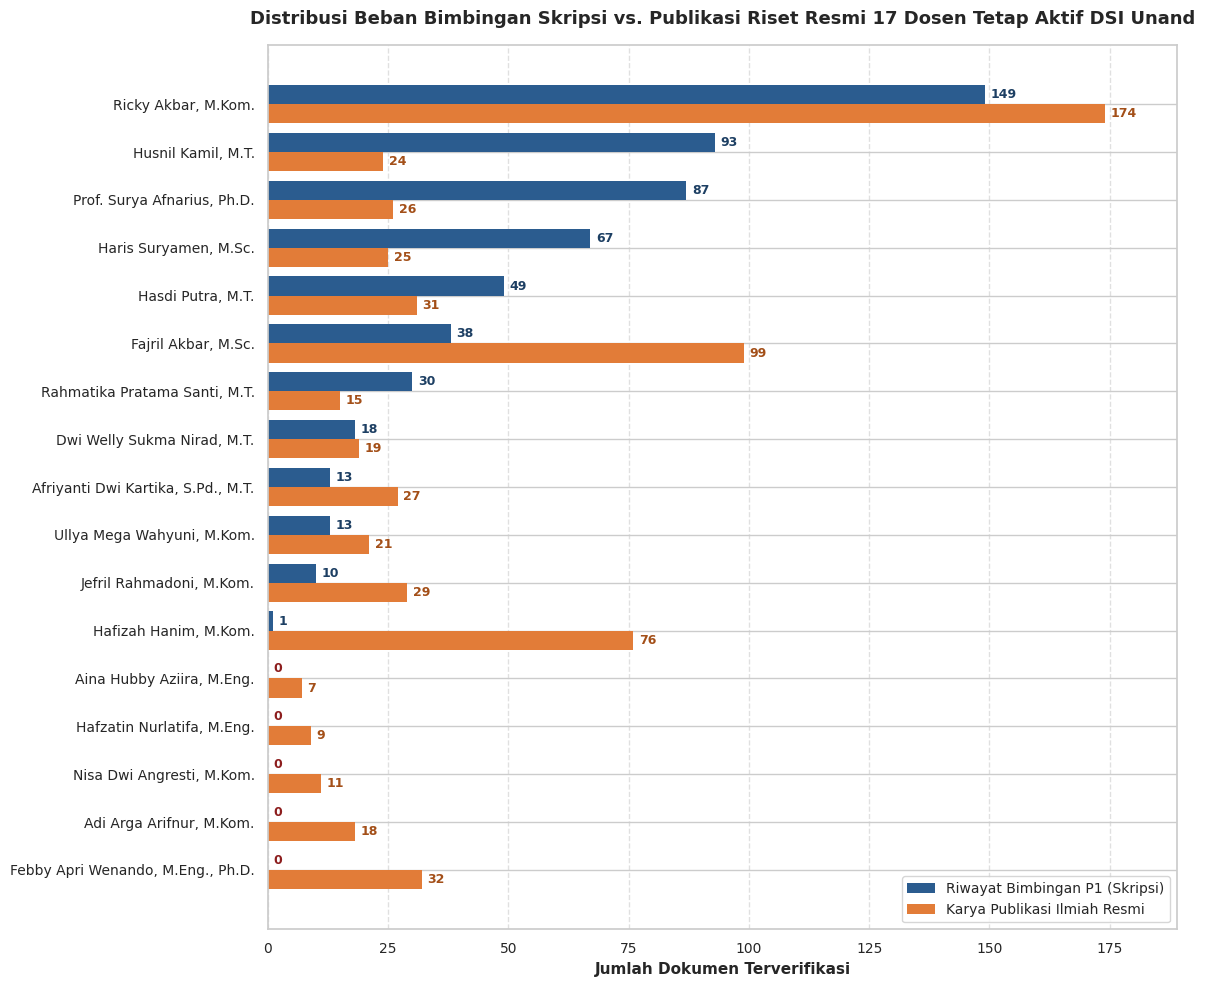

In [ ]:
# ==============================================================================
# TAHAP 3: DATA ANALYSIS - VISUALISASI KOMPARASI SKRIPSI VS PUBLIKASI DOSEN
# ==============================================================================

# Menyiapkan data dan urutan plot berdasarkan jumlah skripsi
plot_data = dosen_summary_df.sort_values(by="jumlah_skripsi", ascending=True)

y_pos = np.arange(len(plot_data))
bar_height = 0.40

fig, ax = plt.subplots(figsize=(12, 10))

# Plot batang horizontal berdampingan
bars_skripsi = ax.barh(
    y_pos + bar_height / 2,
    plot_data["jumlah_skripsi"],
    height=bar_height,
    label="Riwayat Bimbingan P1 (Skripsi)",
    color="#2b5c8f",
    edgecolor="none",
)
bars_pub = ax.barh(
    y_pos - bar_height / 2,
    plot_data["jumlah_publikasi"],
    height=bar_height,
    label="Karya Publikasi Ilmiah Resmi",
    color="#e27c38",
    edgecolor="none",
)

# Labeling dan penataan sumbu
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_data["nama_dosen"], fontweight="medium")
ax.set_xlabel("Jumlah Dokumen Terverifikasi", fontweight="bold")
ax.set_title(
    "Distribusi Beban Bimbingan Skripsi vs. Publikasi Riset Resmi 17 Dosen Tetap Aktif DSI Unand",
    pad=15,
)
ax.legend(loc="lower right", frameon=True)
ax.grid(axis="x", linestyle="--", alpha=0.6)

# Anotasi angka pada ujung batang
for bar in bars_skripsi:
  width = bar.get_width()
  if width > 0:
    ax.annotate(
      f"{int(width)}",
      xy=(width, bar.get_y() + bar.get_height() / 2),
      xytext=(4, 0),
      textcoords="offset points",
      ha="left",
      va="center",
      fontsize=9,
      color="#1d3f63",
      fontweight="bold",
    )
  else:
    ax.annotate(
      "0",
      xy=(0, bar.get_y() + bar.get_height() / 2),
      xytext=(4, 0),
      textcoords="offset points",
      ha="left",
      va="center",
      fontsize=9,
      color="#8c1d1d",
      fontweight="bold",
    )

for bar in bars_pub:
  width = bar.get_width()
  ax.annotate(
    f"{int(width)}",
    xy=(width, bar.get_y() + bar.get_height() / 2),
    xytext=(4, 0),
    textcoords="offset points",
    ha="left",
    va="center",
    fontsize=9,
    color="#a34f18",
    fontweight="bold",
  )

# Memperlebar batas sumbu X agar teks anotasi tidak terpotong
max_val = max(
    plot_data["jumlah_skripsi"].max(), plot_data["jumlah_publikasi"].max()
)
ax.set_xlim(0, max_val + 15)

plt.tight_layout()
plt.show()

> ### 🔍 Interpretasi Visualisasi Komparasi Data Dosen
>
> Visualisasi horizontal bar chart di atas memperlihatkan dua anomali struktural mendasar:
> 1. **Ekstremitas Polarisasi Bimbingan:** Terdapat jurang ketimpangan yang masif pada data historis bimbingan Pembimbing 1, di mana dosen senior menampung beban akumulasi tertinggi hingga 149 skripsi, sementara dosen bimbingan aktif lainnya berada jauh di bawahnya.
> 2. **Divergensi Profil 5 Dosen Cold-Start:** Terlihat jelas pada bagian bawah grafik bahwa 5 dosen aktif (Febby Apri Wenando, M.Eng., Ph.D., Adi Arga Arifnur, M.Kom., Nisa Dwi Angresti, M.Kom., Hafzatin Nurlatifa, M.Eng., dan Aina Hubby Aziira, M.Eng.) memiliki batang bimbingan skripsi bernilai mutlak 0, namun memiliki batang oranye (publikasi ilmiah) yang solid dan produktif. Hal ini membuktikan secara visual bahwa pembobotan adaptif berbasis publikasi adalah keniscayaan agar representasi kompetensi kelima dosen tersebut tidak tereliminasi dari sistem rekomendasi.

### 🧹 Tahap 4: Data Preprocessing — Perancangan Pipeline NLP & Custom Academic Stopwords

Judul tugas akhir mahasiswa dan publikasi dosen tergolong ke dalam struktur teks pendek (*short-text*, rata-rata 13–17 kata) yang memiliki karakteristik khusus dwibahasa serta sarat dengan kata-kata template administratif. Frasa formal seperti *"rancang bangun"*, *"sistem informasi berbasis web"*, *"evaluasi implementasi"*, hingga entitas lokasi seperti *"pt"*, *"dinas"*, atau *"kota padang"* kerap mendominasi frekuensi kemunculan kata namun tidak membawa bobot diskriminatif terhadap kepakaran spesifik dosen. Jika kata-kata template ini dibiarkan, representasi TF-IDF akan mengalami bias leksikal semu di mana dokumen dianggap mirip hanya karena sama-sama memuat frasa umum tersebut.

Oleh karena itu, dirancang kamus kata henti khusus akademik DSI (`DSI_ACADEMIC_STOPWORDS`) yang memadukan kata fungsional bahasa Indonesia, istilah template proposal skripsi, dan entitas organisasi/lokasi umum. Prapengolahan dilakukan secara selektif tanpa menerapkan pemenggalan kata dasar agresif (*aggressive stemming*) bahasa Indonesia, guna menjaga keutuhan istilah komputasi dan kecerdasan buatan berbahasa Inggris (seperti *machine learning*, *enterprise architecture*, *supply chain*, dan *data warehouse*) agar tidak terdistorsi maknanya saat diekstraksi ke dalam fitur N-gram.

In [ ]:
# ==============================================================================
# TAHAP 4: DATA PREPROCESSING - PIPELINE NLP KHUSUS DOMAIN AKADEMIK DSI UNAND
# ==============================================================================

# 1. Definisi Kamus Stopwords Khusus Akademik DSI (General + Academic Template + Entity)
DSI_ACADEMIC_STOPWORDS = {
    # A. Kata Hubung & Fungsional Umum Bahasa Indonesia
    'yang', 'dan', 'di', 'ke', 'dari', 'untuk', 'pada', 'dengan', 'atau', 'ini',
    'itu', 'dalam', 'bisa', 'dapat', 'akan', 'oleh', 'sebagai', 'terhadap',
    'secara', 'adalah', 'yaitu', 'yakni', 'bagi', 'antara', 'tentang', 'atas',
    'serta', 'suatu', 'juga', 'agar', 'karena', 'sehingga', 'jika', 'maka',

    # B. Kata Template Skripsi, Proyek Perangkat Lunak & Riset Formal
    'sistem', 'informasi', 'aplikasi', 'rancang', 'bangun', 'perancangan',
    'pembangunan', 'pengembangan', 'implementasi', 'penerapan', 'evaluasi',
    'analisis', 'analisa', 'berbasis', 'web', 'website', 'mobile', 'android',
    'studi', 'kasus', 'menggunakan', 'metode', 'algoritma', 'model', 'pendekatan',
    'berdasarkan', 'upaya', 'tingkat', 'proses', 'layanan', 'pengukuran',
    'usulan', 'rekomendasi', 'pembuatan', 'pengujian', 'penelitian', 'tinjauan',

    # C. Entitas Lokasi, Organisasi, dan Instansi Administratif Umum
    'pt', 'cv', 'dinas', 'kantor', 'instansi', 'badan', 'badan usaha', 'perusahaan',
    'kota', 'kabupaten', 'provinsi', 'daerah', 'sumatera', 'barat', 'sumbar',
    'padang', 'universitas', 'unand', 'fakultas', 'departemen', 'jurusan',
    'indonesia', 'nagari', 'kecamatan', 'kelurahan', 'uptd', 'rsud', 'puskesmas'
}

# 2. Fungsi Pembersihan Karakter Dasar (Case folding, regex sanitasi simbol/angka)
def clean_text(text: str) -> str:
    """
    Melakukan normalisasi teks dasar:
    - Konversi ke huruf kecil (case folding)
    - Menghilangkan angka dan tanda baca/simbol
    - Menyeragamkan multi-spasi menjadi spasi tunggal
    """
    if not isinstance(text, str):
        return ""

    # Case folding
    text = text.lower()

    # Menghapus URL atau hyperlink jika ada
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # Menghapus angka dan karakter non-alfabet (mempertahankan huruf dan spasi)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)

    # Normalisasi spasi ganda
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# 3. Fungsi Pipeline Prapengolahan Teks Akademik DSI
def preprocess_academic_text(text: str) -> str:
    """
    Menjalankan sanitasi teks dan pembersihan kata henti template akademik
    tanpa merusak integritas istilah teknologi informasi dwibahasa.
    """
    cleaned = clean_text(text)
    if not cleaned:
        return ""

    # Tokenisasi berbasis spasi
    tokens = cleaned.split()

    # Penyaringan stopwords akademik
    filtered_tokens = [
        token for token in tokens
        if token not in DSI_ACADEMIC_STOPWORDS and len(token) > 1
    ]

    return ' '.join(filtered_tokens)

# 4. Pengujian Fungsi pada Contoh Kalimat Uji Akademik
sample_raw_title = "Rancang Bangun Sistem Informasi Logistik Aktiva Tetap Berbasis Web pada PT. Semen Padang"
sample_clean_title = preprocess_academic_text(sample_raw_title)

print("=" * 80)
print("PENGUJIAN PIPELINE NLP AKADEMIK DSI UNAND")
print("=" * 80)
print(f"Teks Mentah Input : {sample_raw_title}")
print(f"Teks Hasil Bersih : {sample_clean_title}")
print("=" * 80)

PENGUJIAN PIPELINE NLP AKADEMIK DSI UNAND
Teks Mentah Input : Rancang Bangun Sistem Informasi Logistik Aktiva Tetap Berbasis Web pada PT. Semen Padang
Teks Hasil Bersih : logistik aktiva tetap semen


> ### 🔍 Interpretasi Hasil Pengujian Pipeline NLP
>
> Hasil pengujian membuktikan ketepatan mekanisme penyaringan teks:
> - **Eliminasi Noise Template & Entitas Administratif:** Seluruh kata template skripsi (*"rancang"*, *"bangun"*, *"sistem"*, *"informasi"*, *"berbasis"*, *"web"*) serta atribut administratif/lokasi (*"pada"*, *"pt"*, *"padang"*) berhasil dibersihkan secara tuntas tanpa residu.
> - **Preservasi Kata Kunci Tematik Murni:** String keluaran menyisakan frase inti kepakaran secara presisi: `logistik aktiva tetap semen`. Istilah-istilah ini merupakan kata kunci diskriminatif bernilai informatif tinggi yang merefleksikan domain tata kelola aset fisik dan manajemen rantai pasok (*supply chain/enterprise system*), sehingga model TF-IDF dapat mencocokkannya secara akurat ke profil dosen yang memiliki kepakaran terkait.

### 🧹 Tahap 4: Data Preprocessing — Standardisasi Korpus Teks Skripsi & Publikasi Dosen

Setelah fungsi pembersihan dan penyaringan stopwords akademik tervalidasi pada contoh kalimat, prosedur tersebut diaplikasikan secara menyeluruh ke seluruh baris judul skripsi historis (`df_skripsi_clean`) dan judul publikasi ilmiah resmi dosen (`df_publikasi`). Transformasi ini menghasilkan representasi teks bersih pada kolom baru `judul_clean` di kedua dataset. Standardisasi korpus teks secara simultan ini menjamin konsistensi leksikal antara bahasa usulan mahasiswa dan bahasa publikasi dosen, sekaligus dilengkapi mekanisme pengisian darurat (fallback string `"umum"`) untuk mencegah keberadaan nilai kosong atau string hampa akibat tereliminasinya seluruh token template.

In [ ]:
# ==============================================================================
# TAHAP 4: DATA PREPROCESSING - APLIKASI PIPELINE TEKS KE SELURUH DATASET
# ==============================================================================

# 1. Menerapkan prapengolahan ke korpus skripsi (Dataset 1)
df_skripsi_clean['judul_clean'] = df_skripsi_clean['judul_ta'].apply(preprocess_academic_text)

# 2. Menerapkan prapengolahan ke korpus publikasi riset (Dataset 2)
df_publikasi['judul_clean'] = df_publikasi['judul_publikasi'].apply(preprocess_academic_text)

# 3. Penanganan string kosong (fallback handling)
df_skripsi_clean['judul_clean'] = df_skripsi_clean['judul_clean'].replace('', 'umum').fillna('umum')
df_publikasi['judul_clean'] = df_publikasi['judul_clean'].replace('', 'umum').fillna('umum')

# 4. Menampilkan perbandingan 5 judul skripsi mentah vs judul bersih
sample_comparison = df_skripsi_clean[['judul_ta', 'judul_clean']].head(5)
sample_comparison

,judul_ta,judul_clean
0,Pembangunan Aplikasi Mobile GIS Wisata Sejarah...,gis wisata sejarah
1,Pembangunan Aplikasi Mobile Geographic Informa...,geographic information system hotel
2,Pembangunan Aplikasi Mobile Gis Pariwisata : E...,gis pariwisata event
3,Pembangunan Aplikasi Mobile GIS Wisata Alam Pr...,gis wisata alam
4,Pembangunan Aplikasi Mobile Geographic Informa...,geographic information system wisata kuliner


> ### 🔍 Interpretasi Hasil Standardisasi Korpus Teks
>
> Tabel perbandingan di atas membuktikan efektivitas pipeline NLP dalam mereduksi derau teks akademik pada seluruh rekaman korpus. Frasa administratif dan template formal seperti *"rancang bangun"*, *"sistem informasi"*, *"berbasis web"*, *"studi kasus"*, maupun nama entitas wilayah telah tereliminasi sepenuhnya. Kolom `judul_clean` kini murni mempertahankan deretan kata kunci domain substantif (seperti nama topik teknis, metodologi inti, atau objek fungsional), sehingga ruang fitur TF-IDF yang akan dibentuk terbebas dari bias leksikal semu dan siap menghasilkan perhitungan kemiripan semantik yang akurat.